In [1]:
from itertools import combinations

baskets = [
    ["tea", "sugar", "milk"],
    ["tea", "sugar"],
    ["bread", "butter", "milk"],
    ["tea", "milk"],
    ["bread", "butter"],
    ["tea", "sugar", "bread"],
]

def support(itemset, baskets):
    """The share of baskets that hold every item in the itemset."""
    return sum(set(itemset) <= set(basket) for basket in baskets) / len(baskets)

for itemset in [("tea",), ("tea", "sugar"), ("bread", "butter"), ("tea", "butter")]:
    print(f"{' + '.join(itemset):16} support = {support(itemset, baskets):.2f}")

tea              support = 0.67
tea + sugar      support = 0.50
bread + butter   support = 0.33
tea + butter     support = 0.00


In [2]:
items = sorted({item for basket in baskets for item in basket})
min_support = 0.5

for size in (1, 2, 3):
    for itemset in combinations(items, size):
        s = support(itemset, baskets)
        if s >= min_support:
            print(f"{' + '.join(itemset):16} {s:.2f}")

bread            0.50
milk             0.50
sugar            0.50
tea              0.67
sugar + tea      0.50


In [3]:
from math import comb

for size in (2, 3, 4, 5):
    print(f"itemsets of {size} items out of 1,000 items: {comb(1000, size):>20,}")

itemsets of 2 items out of 1,000 items:              499,500
itemsets of 3 items out of 1,000 items:          166,167,000
itemsets of 4 items out of 1,000 items:       41,417,124,750
itemsets of 5 items out of 1,000 items:    8,250,291,250,200


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import dataclass
from typing import Optional

from thilimarketbasket.catalog_data import CATEGORIES

In [5]:
summary = pd.DataFrame(
    [{"category": name,
      "products": len(spec["products"]),
      "brands": len(spec["brands"]),
      "default pack sizes": ", ".join(spec["sizes"])}
     for name, spec in CATEGORIES.items()]
).set_index("category")

print(f"{summary['products'].sum()} products in {len(summary)} categories\n")
summary

127 products in 12 categories



,products,brands,default pack sizes
category,,,
Staples,14,6,"500 g, 1 kg, 5 kg"
Pulses,10,6,"500 g, 1 kg, 5 kg"
Oils and Ghee,7,6,"500 ml, 1 L, 5 L"
Spices,14,6,"sachet 10 g, 100 g, 200 g"
Dairy and Eggs,7,5,"200 g, 500 g"
Bakery and Breakfast,7,5,"100 g, 200 g, 400 g"
Snacks and Instant Food,10,6,"Rs 5 pack, Rs 10 pack, 150 g"
Beverages,10,6,"250 g, 500 g"
Fresh Produce,17,0,"500 g, 1 kg"


In [6]:
pulses = CATEGORIES["Pulses"]
print("brands:", ", ".join(pulses["brands"]))
print("pack sizes:", ", ".join(pulses["sizes"]))
print("\nproducts:")
for product in pulses["products"]:
    print("  ", product)

brands: Surya Grains, Kaveri Valley, Annadata, Maitri Foods, Shubham Select, Pragati
pack sizes: 500 g, 1 kg, 5 kg

products:
   ('Toor Dal', 20)
   ('Moong Dal', 10)
   ('Chana Dal', 8)
   ('Urad Dal', 8)
   ('Masoor Dal', 7)
   ('Rajma', 4)
   ('Kabuli Chana', 4)
   ('Green Moong', 3)
   ('Black Chana', 3)
   ('Lobia', 2)


In [7]:
brands = list(pulses["brands"])
sizes = list(pulses["sizes"])
possible = [f"{brand} Toor Dal {size}" for brand in brands for size in sizes]

print(f"{len(brands)} brands x {len(sizes)} pack sizes = {len(possible)} possible SKUs of Toor Dal, for example:")
for name in possible[:6]:
    print("  ", name)

6 brands x 3 pack sizes = 18 possible SKUs of Toor Dal, for example:
   Surya Grains Toor Dal 500 g
   Surya Grains Toor Dal 1 kg
   Surya Grains Toor Dal 5 kg
   Kaveri Valley Toor Dal 500 g
   Kaveri Valley Toor Dal 1 kg
   Kaveri Valley Toor Dal 5 kg


In [8]:
@dataclass(frozen=True)
class Item:
    """One SKU: a product, in one brand and one pack size."""
    name: str               # the full name a model will read, e.g. "Surya Grains Toor Dal 1 kg"
    base: str               # the product without brand or size, e.g. "Toor Dal"
    category: str           # e.g. "Pulses"
    brand: Optional[str]    # None for loose goods such as fresh produce
    size: str               # e.g. "1 kg", "Rs 2 sachet", "dozen"


def split(product):
    """A product is (name, weight) or (name, weight, {size: weight}) when it has its own pack sizes."""
    return product if len(product) == 3 else (product[0], product[1], None)


def all_skus(brands_per_product, rng):
    skus = []
    for category, spec in CATEGORIES.items():
        brand_names = list(spec["brands"])
        brand_weights = np.array(list(spec["brands"].values()), dtype=float)
        for product in spec["products"]:
            base, _, own_sizes = split(product)
            sizes = own_sizes or spec["sizes"]
            if brand_names:
                # pick this many brands, big brands more likely, none twice
                k = min(brands_per_product, len(brand_names))
                picked = rng.choice(len(brand_names), size=k, replace=False,
                                    p=brand_weights / brand_weights.sum())
                brands = [brand_names[i] for i in sorted(picked)]
            else:
                brands = [None]          # sold loose
            for brand in brands:
                for size in sizes:
                    name = " ".join(part for part in (brand, base, size) if part)
                    skus.append(Item(name=name, base=base, category=category, brand=brand, size=size))
    return skus

In [9]:
import numpy as np

# 1. Instantiate the modern PCG64 generator with a seed
rng = np.random.default_rng(seed=42)

# 2. Generate a variety of data types efficiently
uniform_floats = rng.random(size=5)
bounded_integers = rng.integers(low=1, high=100, size=5)
normal_distribution = rng.standard_normal(size=5)

# Print results to verify
print("Uniform Floats [0, 1):\n", uniform_floats)
print("\nIntegers [1, 100):\n", bounded_integers)
print("\nStandard Normal Distributions:\n", normal_distribution)

Uniform Floats [0, 1):
 [0.77395605 0.43887844 0.85859792 0.69736803 0.09417735]

Integers [1, 100):
 [53 97 73 76 72]

Standard Normal Distributions:
 [-0.01680116 -0.85304393  0.87939797  0.77779194  0.0660307 ]


In [10]:
rng = np.random.default_rng(0)
pool = all_skus(4, rng)

print(f"{len(pool):,} SKUs the shop could stock with 4 brands per product\n")
for item in pool[:5]:
    print("  ", item)

1,127 SKUs the shop could stock with 4 brands per product

   Item(name='Kaveri Valley Basmati Rice 500 g', base='Basmati Rice', category='Staples', brand='Kaveri Valley', size='500 g')
   Item(name='Kaveri Valley Basmati Rice 1 kg', base='Basmati Rice', category='Staples', brand='Kaveri Valley', size='1 kg')
   Item(name='Kaveri Valley Basmati Rice 5 kg', base='Basmati Rice', category='Staples', brand='Kaveri Valley', size='5 kg')
   Item(name='Maitri Foods Basmati Rice 500 g', base='Basmati Rice', category='Staples', brand='Maitri Foods', size='500 g')
   Item(name='Maitri Foods Basmati Rice 1 kg', base='Basmati Rice', category='Staples', brand='Maitri Foods', size='1 kg')


In [11]:
def my_make_catalog(n_items=1000, brands_per_product=4, seed=0):
    rng = np.random.default_rng(seed)
    pool = all_skus(brands_per_product, rng)

    by_product = {}   # (category, product) -> positions of its SKUs in the pool
    for position, sku in enumerate(pool):
        by_product.setdefault((sku.category, sku.base), []).append(position)

    if n_items < len(by_product):
        raise ValueError(f"need at least {len(by_product)} items to cover every product, got {n_items}")
    if n_items > len(pool):
        raise ValueError(f"only {len(pool)} SKUs are possible with brands_per_product={brands_per_product}; "
                         f"ask for fewer items or raise brands_per_product")

    chosen = {int(rng.choice(positions)) for positions in by_product.values()}   # one SKU for every product
    rest = [i for i in range(len(pool)) if i not in chosen]
    chosen |= {int(i) for i in rng.choice(rest, size=n_items - len(chosen), replace=False)}
    return [pool[i] for i in sorted(chosen)]


catalog = my_make_catalog()
print(f"{len(catalog):,} items in the catalogue")

1,000 items in the catalogue


In [12]:
from thilimarketbasket.generate import make_catalog as reference_make_catalog

reference = reference_make_catalog()
mine = [(i.name, i.base, i.category, i.brand, i.size) for i in catalog]
theirs = [(i.name, i.base, i.category, i.brand, i.size) for i in reference]

print("same number of items:", len(mine) == len(theirs))
print("identical, item for item:", mine == theirs)
print("every name is unique:", len({i.name for i in catalog}) == len(catalog))

same number of items: True
identical, item for item: True
every name is unique: True


In [13]:
df = pd.DataFrame([vars(item) for item in catalog])
df.sample(10, random_state=1).sort_values(["category", "name"]).reset_index(drop=True)

,name,base,category,brand,size
0,Morning Crisp Bread 400 g,Bread,Bakery and Breakfast,Morning Crisp,400 g
1,Gokul Fresh Curd 200 g,Curd,Dairy and Eggs,Gokul Fresh,200 g
2,Shuddh Phenyl 2 L,Phenyl,Household and Cleaning,Shuddh,2 L
3,Shuddh Toilet Cleaner 1 L,Toilet Cleaner,Household and Cleaning,Shuddh,1 L
4,Dhara Fresh Groundnut Oil 500 ml,Groundnut Oil,Oils and Ghee,Dhara Fresh,500 ml
5,Golden Drop Coconut Oil 1 L,Coconut Oil,Oils and Ghee,Golden Drop,1 L
6,Pure Petal Sanitary Pads pack of 8,Sanitary Pads,Personal Care,Pure Petal,pack of 8
7,Masala Mantra Red Chilli Powder 200 g,Red Chilli Powder,Spices,Masala Mantra,200 g
8,Masala Mantra Sambar Powder 200 g,Sambar Powder,Spices,Masala Mantra,200 g
9,Kaveri Valley Besan 500 g,Besan,Staples,Kaveri Valley,500 g


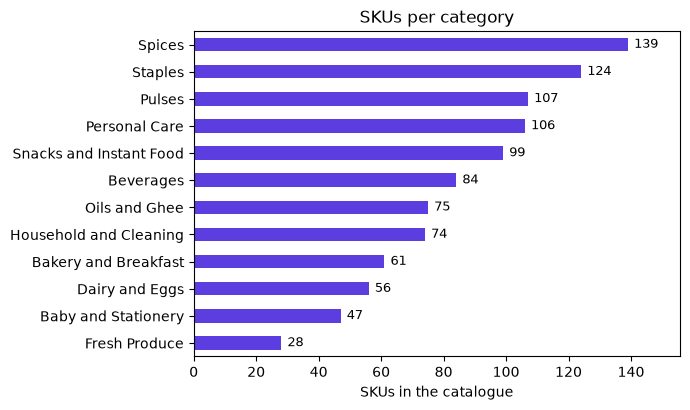

In [14]:
per_category = df.groupby("category").size().sort_values()

fig, ax = plt.subplots(figsize=(7, 4.2))
per_category.plot.barh(ax=ax, color="#5b3de0")
ax.set_xlabel("SKUs in the catalogue")
ax.set_ylabel("")
ax.set_title("SKUs per category")
for position, value in enumerate(per_category):
    ax.text(value + 2, position, str(value), va="center", fontsize=9)
ax.set_xlim(0, per_category.max() * 1.12)
plt.tight_layout()
plt.show()

SKUs per product: fewest 1, median 8, most 12
loose goods with no brand: 28 SKUs
sachets and small rupee packs: 116 SKUs


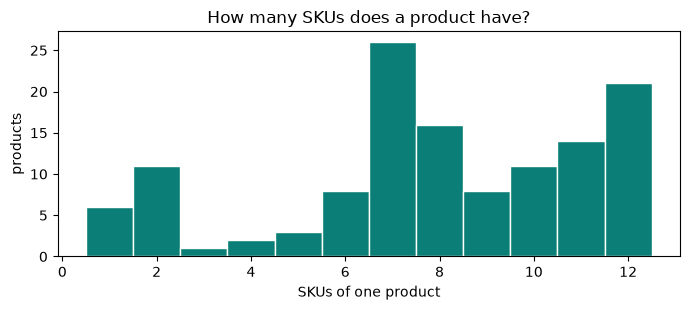

In [15]:
per_product = df.groupby(["category", "base"]).size()

print(f"SKUs per product: fewest {per_product.min()}, median {int(per_product.median())}, most {per_product.max()}")
print(f"loose goods with no brand: {df['brand'].isna().sum()} SKUs")
print(f"sachets and small rupee packs: {df['size'].str.contains('sachet|^Rs ', regex=True).sum()} SKUs")

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(per_product, bins=range(1, int(per_product.max()) + 2), color="#0b7f77", edgecolor="white", align="left")
ax.set_xlabel("SKUs of one product")
ax.set_ylabel("products")
ax.set_title("How many SKUs does a product have?")
plt.tight_layout()
plt.show()

In [16]:
for k in (1, 2, 4, 6):
    pool_k = all_skus(k, np.random.default_rng(0))
    print(f"brands_per_product={k}: {len(pool_k):>5,} possible SKUs")

brands_per_product=1:   305 possible SKUs
brands_per_product=2:   579 possible SKUs
brands_per_product=4: 1,127 possible SKUs
brands_per_product=6: 1,565 possible SKUs


In [17]:
for bad in (5000, 100):
    try:
        my_make_catalog(n_items=bad)
    except ValueError as error:
        print(f"n_items={bad}: ValueError: {error}")

n_items=5000: ValueError: only 1127 SKUs are possible with brands_per_product=4; ask for fewer items or raise brands_per_product
n_items=100: ValueError: need at least 127 items to cover every product, got 100


In [18]:
import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from thilimarketbasket.catalog_data import CATEGORIES
from thilimarketbasket.generate import make_catalog, popularity as reference_popularity

catalog = make_catalog()
print(f"{len(catalog):,} SKUs in the catalogue")

1,000 SKUs in the catalogue


In [19]:
pulses = CATEGORIES["Pulses"]
print("category weight:", pulses["weight"], "(out of", sum(c["weight"] for c in CATEGORIES.values()), "across all categories)")
print("brand weights: ", pulses["brands"])
print("size weights:  ", pulses["sizes"])
print("product weights:")
for product in pulses["products"][:4]:
    print("  ", product)

category weight: 8 (out of 101 across all categories)
brand weights:  {'Surya Grains': 8, 'Kaveri Valley': 5, 'Annadata': 3, 'Maitri Foods': 2, 'Shubham Select': 1.5, 'Pragati': 1}
size weights:   {'500 g': 3, '1 kg': 6, '5 kg': 2}
product weights:
   ('Toor Dal', 20)
   ('Moong Dal', 10)
   ('Chana Dal', 8)
   ('Urad Dal', 8)


In [20]:
def fraction(weights, chosen, stocked):
    """The share of `chosen` among the `stocked` options, using the weights given."""
    return weights[chosen] / sum(weights[option] for option in stocked)


def level_shares(item, catalog, categories=CATEGORIES):
    """The four fractions for one SKU: category, product, brand, size. Each is a share of its own level."""
    spec = categories[item.category]

    products_here = [it for it in catalog if it.category == item.category]
    stocked_products = {it.base for it in products_here}
    product_weights, size_weights = {}, {}
    for product in spec["products"]:
        name, weight = product[0], product[1]
        product_weights[name] = weight
        size_weights[name] = product[2] if len(product) == 3 else spec["sizes"]

    category = spec["weight"] / sum(c["weight"] for c in categories.values())
    product = fraction(product_weights, item.base, stocked_products)

    if item.brand is None:       # sold loose: no brand to choose
        brand = 1.0
    else:
        stocked_brands = {it.brand for it in products_here if it.base == item.base}
        brand = fraction(spec["brands"], item.brand, stocked_brands)

    stocked_sizes = {it.size for it in products_here if it.base == item.base and it.brand == item.brand}
    size = fraction(size_weights[item.base], item.size, stocked_sizes)
    return category, product, brand, size

In [21]:
def my_popularity(catalog, categories=CATEGORIES):
    """One share per SKU, in catalogue order, adding up to 1."""
    shares = np.array([np.prod(level_shares(item, catalog, categories)) for item in catalog])
    return shares / shares.sum()


shares = my_popularity(catalog)
print("shares add up to", round(shares.sum(), 6))

shares add up to 1.0


In [22]:
reference = reference_popularity(catalog)
print("same as the reference:", np.allclose(shares, reference, rtol=0, atol=1e-12))
print("largest difference:   ", float(np.abs(shares - reference).max()))

same as the reference: True
largest difference:    0.0


In [24]:
sku = next(item for item in catalog if item.name == "Kaveri Valley Toor Dal 1 kg")
c, p, b, s = level_shares(sku, catalog)

print(sku.name, "\n")
print(f"  category share  {c:.4f}   Pulses is {c:.1%} of the shop's sales")
print(f"  product share   {p:.4f}   Toor Dal is {p:.1%} of Pulses")
print(f"  brand share     {b:.4f}   Kaveri Valley is {b:.1%} of the Toor Dal that is stocked")
print(f"  size share      {s:.4f}   1 kg is {s:.1%} of Kaveri Valley Toor Dal")
print(f"  {'':16}{'-' * 8}")
print(f"  SKU share       {c * p * b * s:.5f}  = {c * p * b * s:.2%} of all sales")

Kaveri Valley Toor Dal 1 kg 

  category share  0.0792   Pulses is 7.9% of the shop's sales
  product share   0.2899   Toor Dal is 29.0% of Pulses
  brand share     0.3226   Kaveri Valley is 32.3% of the Toor Dal that is stocked
  size share      0.5455   1 kg is 54.5% of Kaveri Valley Toor Dal
                  --------
  SKU share       0.00404  = 0.40% of all sales


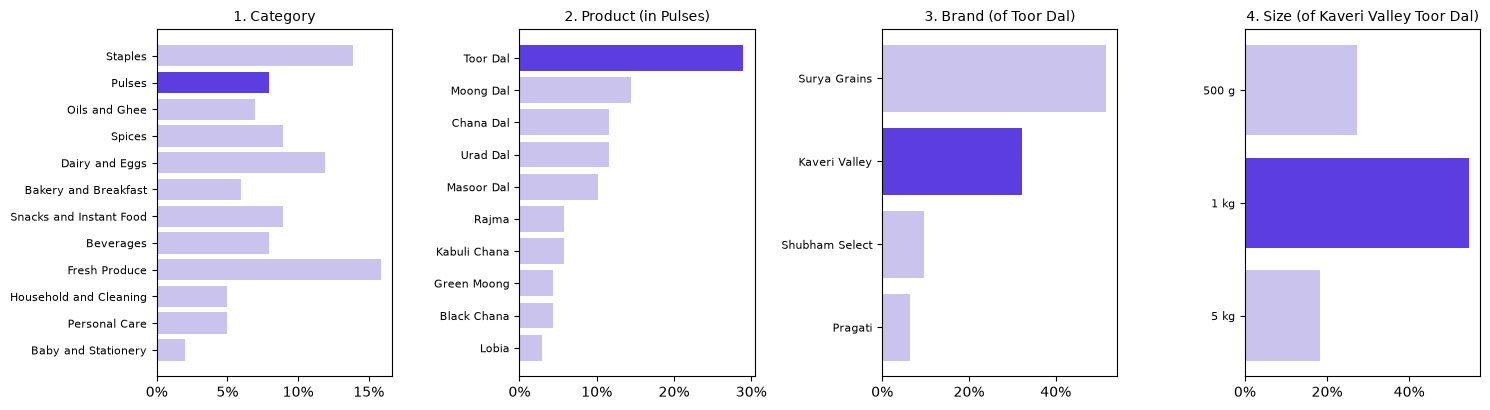

In [25]:
def bars(ax, labels, values, highlight, title):
    colors = ["#5b3de0" if label == highlight else "#c9c3ee" for label in labels]
    ax.barh(range(len(labels)), values, color=colors)
    ax.set_yticks(range(len(labels)), labels, fontsize=8)
    ax.invert_yaxis()
    ax.set_title(title, fontsize=10)
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")


stocked_toor = {it.brand for it in catalog if it.base == "Toor Dal"}
stocked_sizes = {it.size for it in catalog if it.base == "Toor Dal" and it.brand == "Kaveri Valley"}

cat_w = {name: spec["weight"] for name, spec in CATEGORIES.items()}
prod_w = {p[0]: p[1] for p in pulses["products"]}
brand_w = {k: v for k, v in pulses["brands"].items() if k in stocked_toor}
size_w = {k: v for k, v in pulses["sizes"].items() if k in stocked_sizes}

fig, axes = plt.subplots(1, 4, figsize=(15, 4.2))
for ax, weights, highlight, title in zip(
        axes, (cat_w, prod_w, brand_w, size_w), ("Pulses", "Toor Dal", "Kaveri Valley", "1 kg"),
        ("1. Category", "2. Product (in Pulses)", "3. Brand (of Toor Dal)", "4. Size (of Kaveri Valley Toor Dal)")):
    total = sum(weights.values())
    bars(ax, list(weights), [w / total for w in weights.values()], highlight, title)
plt.tight_layout()
plt.show()

In [26]:
def product_share(catalog, shares, base):
    return sum(share for item, share in zip(catalog, shares) if item.base == base)

for brands in (1, 2, 4, 6):
    other = make_catalog(n_items=300, brands_per_product=brands)
    other_shares = reference_popularity(other)
    print(f"{brands} brand(s) per product: {len(other):>5,} items, "
          f"Toor Dal = {product_share(other, other_shares, 'Toor Dal'):.4f} of sales, "
          f"Milk = {product_share(other, other_shares, 'Milk'):.4f}")

1 brand(s) per product:   300 items, Toor Dal = 0.0230 of sales, Milk = 0.0475
2 brand(s) per product:   300 items, Toor Dal = 0.0230 of sales, Milk = 0.0475
4 brand(s) per product:   300 items, Toor Dal = 0.0230 of sales, Milk = 0.0475
6 brand(s) per product:   300 items, Toor Dal = 0.0230 of sales, Milk = 0.0475


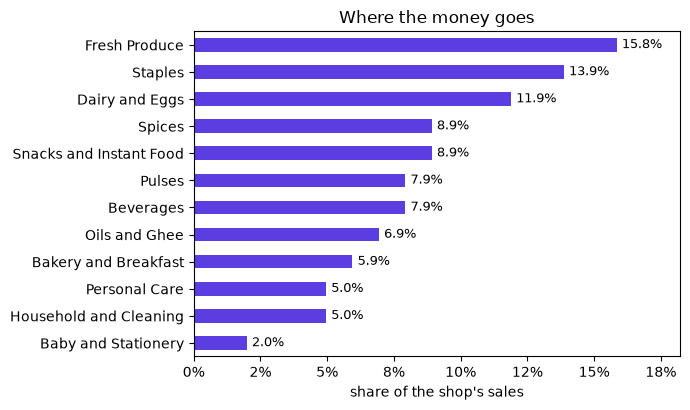

In [27]:
df = pd.DataFrame([vars(item) for item in catalog])
df["share"] = shares

by_category = df.groupby("category")["share"].sum().sort_values()

fig, ax = plt.subplots(figsize=(7, 4.2))
by_category.plot.barh(ax=ax, color="#5b3de0")
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_xlabel("share of the shop's sales")
ax.set_ylabel("")
ax.set_title("Where the money goes")
for position, value in enumerate(by_category):
    ax.text(value + 0.002, position, f"{value:.1%}", va="center", fontsize=9)
ax.set_xlim(0, by_category.max() * 1.15)
plt.tight_layout()
plt.show()

In [28]:
ranked = np.sort(shares)[::-1]
rank = np.arange(1, len(ranked) + 1)

print("The ten best sellers:")
print(df.sort_values("share", ascending=False).head(10)[["name", "share"]].to_string(index=False, float_format=lambda x: f"{x:.2%}"))
print("\nThe five slowest:")
print(df.sort_values("share").head(5)[["name", "share"]].to_string(index=False, float_format=lambda x: f"{x:.4%}"))
print(f"\nbest seller / slowest seller: {ranked[0] / ranked[-1]:.0f} to 1")

The ten best sellers:
                      name  share
                Onion 1 kg  1.41%
               Tomato 1 kg  1.32%
               Potato 1 kg  1.32%
   Gokul Fresh Milk 500 ml  1.27%
    Coriander Leaves bunch  1.19%
Surya Grains Toor Dal 1 kg  1.18%
               Onion 500 g  1.13%
              Tomato 500 g  1.05%
              Potato 500 g  1.05%
   Kaveri Valley Salt 1 kg  1.02%

The five slowest:
                          name   share
            Pragati Lobia 5 kg 0.0026%
   Amrit Kalash Vanaspati 5 kg 0.0028%
    Tulsi Tara Hair Oil 500 ml 0.0030%
Tulsi Tara Talcum Powder 200 g 0.0030%
 Kids Korner Baby Cereal 400 g 0.0032%

best seller / slowest seller: 541 to 1


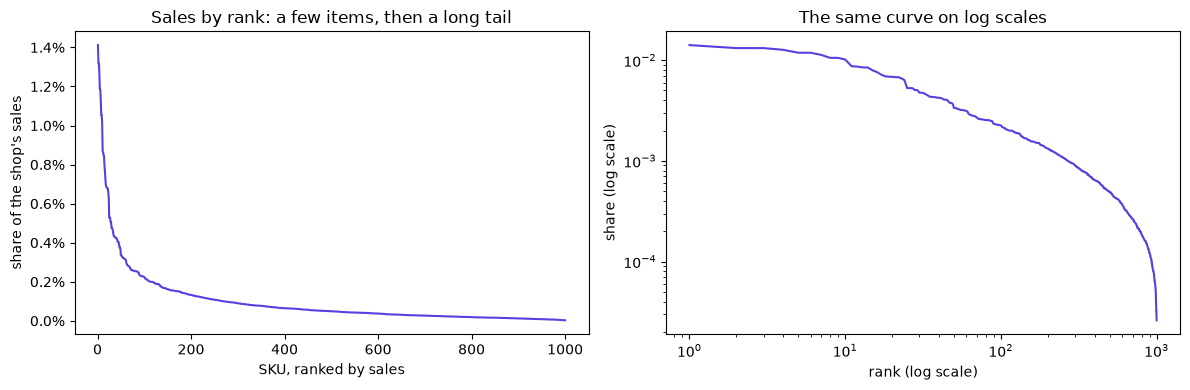

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(rank, ranked, color="#5b3de0")
axes[0].set_xlabel("SKU, ranked by sales")
axes[0].set_ylabel("share of the shop's sales")
axes[0].yaxis.set_major_formatter(lambda y, _: f"{y:.1%}")
axes[0].set_title("Sales by rank: a few items, then a long tail")

axes[1].loglog(rank, ranked, color="#5b3de0")
axes[1].set_xlabel("rank (log scale)")
axes[1].set_ylabel("share (log scale)")
axes[1].set_title("The same curve on log scales")

plt.tight_layout()
plt.show()

top   1% of SKUs ( 10 items) make 12% of sales
top   5% of SKUs ( 50 items) make 34% of sales
top  10% of SKUs (100 items) make 47% of sales
top  20% of SKUs (200 items) make 64% of sales
top  50% of SKUs (500 items) make 88% of sales

114 SKUs make half the sales, 365 make 80%


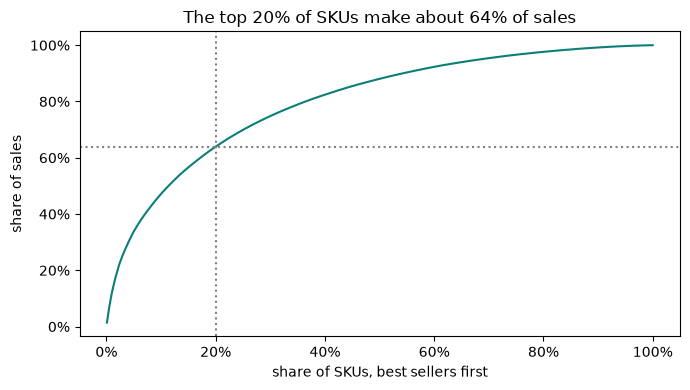

In [30]:
from thilimarketbasket.generate import head_share

cumulative = np.cumsum(ranked)
for top in (0.01, 0.05, 0.10, 0.20, 0.50):
    print(f"top {top:>4.0%} of SKUs ({int(top * len(ranked)):>3} items) make {head_share(shares, top):.0%} of sales")

half = int((cumulative < 0.5).sum() + 1)
eighty = int((cumulative < 0.8).sum() + 1)
print(f"\n{half} SKUs make half the sales, {eighty} make 80%")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(rank / len(rank), cumulative, color="#0b7f77")
ax.axvline(0.2, color="grey", linestyle=":")
ax.axhline(head_share(shares, 0.2), color="grey", linestyle=":")
ax.set_xlabel("share of SKUs, best sellers first")
ax.set_ylabel("share of sales")
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.set_title("The top 20% of SKUs make about 64% of sales")
plt.tight_layout()
plt.show()

In [31]:
sachet = df["size"].str.contains("sachet|^Rs ", regex=True)

print(f"{sachet.sum()} sachet and rupee-pack SKUs ({sachet.mean():.1%} of the catalogue)")
print(f"together they make {df.loc[sachet, 'share'].sum():.1%} of sales")
print(f"an average sachet SKU: {df.loc[sachet, 'share'].mean():.3%}; an average SKU overall: {df['share'].mean():.3%}")

116 sachet and rupee-pack SKUs (11.6% of the catalogue)
together they make 11.8% of sales
an average sachet SKU: 0.102%; an average SKU overall: 0.100%


In [32]:
edited = copy.deepcopy(CATEGORIES)
edited["Pulses"]["brands"]["Surya Grains"] = 16

before = shares
after = my_popularity(catalog, edited)

surya = np.array([item.brand == "Surya Grains" and item.category == "Pulses" for item in catalog])
toor = np.array([item.base == "Toor Dal" for item in catalog])

print(f"Surya Grains pulses: {before[surya].sum():.2%} -> {after[surya].sum():.2%} of sales")
print(f"Toor Dal as a whole: {before[toor].sum():.2%} -> {after[toor].sum():.2%} of sales")

Surya Grains pulses: 3.66% -> 4.78% of sales
Toor Dal as a whole: 2.30% -> 2.30% of sales


In [33]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from thilimarketbasket.generate import make_catalog, popularity, background_baskets
from thilimarketbasket.mine import frequent_itemsets

catalog = make_catalog()
shares = popularity(catalog)
names = [item.name for item in catalog]
print(f"{len(catalog):,} SKUs, shares add up to {shares.sum():.0f}")

1,000 SKUs, shares add up to 1


mean 8.01, median 7, 95th percentile 15, largest 40, smallest 2


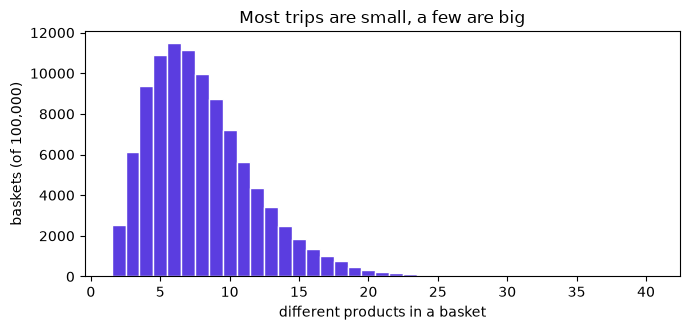

In [34]:
def my_basket_sizes(n_baskets, rng, mean=8.0, dispersion=4.0, minimum=2):
    """How many different products each basket holds."""
    extra_mean = mean - minimum
    p = dispersion / (dispersion + extra_mean)       # numpy's parameterisation of the negative binomial
    return minimum + rng.negative_binomial(dispersion, p, size=n_baskets)


rng = np.random.default_rng(0)
sizes = my_basket_sizes(100_000, rng)

print(f"mean {sizes.mean():.2f}, median {int(np.median(sizes))}, "
      f"95th percentile {int(np.percentile(sizes, 95))}, largest {sizes.max()}, smallest {sizes.min()}")

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist(sizes, bins=range(2, sizes.max() + 2), color="#5b3de0", edgecolor="white", align="left")
ax.set_xlabel("different products in a basket")
ax.set_ylabel("baskets (of 100,000)")
ax.set_title("Most trips are small, a few are big")
plt.tight_layout()
plt.show()

In [35]:
by_product = {}           # (category, product) -> positions of its SKUs in the catalogue
for position, item in enumerate(catalog):
    by_product.setdefault((item.category, item.base), []).append(position)

product_keys = list(by_product)
skus_of = [np.array(by_product[key]) for key in product_keys]
product_share = np.array([shares[s].sum() for s in skus_of])

print(f"{len(product_keys)} products, shares add up to {product_share.sum():.0f}")
print("most popular:", [key[1] for key in np.array(product_keys, dtype=object)[np.argsort(-product_share)[:5]]])

127 products, shares add up to 1
most popular: ['Milk', 'Sunflower Oil', 'Salt', 'Wheat Flour (Atta)', 'Onion']


In [36]:
rng = np.random.default_rng(1)
product_of = np.empty(len(catalog), dtype=int)
for number, skus in enumerate(skus_of):
    product_of[skus] = number

trials, same = 5000, 0
for _ in range(trials):
    picked = rng.choice(len(catalog), size=8, replace=False, p=shares)
    same += len(set(product_of[picked])) < 8
print(f"{same / trials:.0%} of direct-SKU baskets hold two brands or sizes of one product")

26% of direct-SKU baskets hold two brands or sizes of one product


In [37]:
def pick_products(k, rng):
    """k different products, popular ones more likely."""
    return rng.choice(len(product_keys), size=k, replace=False, p=product_share)


print([product_keys[i][1] for i in pick_products(8, np.random.default_rng(3))])

['Poha', 'Sunflower Oil', 'Green Chilli', 'Potato Chips', 'Curd', 'Eggs', 'Toor Dal', 'Potato']


In [38]:
def pick_sku(product, rng):
    """One SKU position for a product, with probability proportional to the SKUs' shares."""
    skus = skus_of[product]
    return rng.choice(skus, p=shares[skus] / shares[skus].sum())


toor = product_keys.index(("Pulses", "Toor Dal"))
tally = pd.Series([names[pick_sku(toor, rng)] for _ in range(20_000)]).value_counts(normalize=True)
print(tally.head(5).to_string(float_format=lambda x: f"{x:.1%}"))

Surya Grains Toor Dal 1 kg      51.4%
Kaveri Valley Toor Dal 1 kg     17.8%
Kaveri Valley Toor Dal 500 g     8.6%
Shubham Select Toor Dal 500 g    5.9%
Kaveri Valley Toor Dal 5 kg      5.9%


In [39]:
QUANTITY_PROBS = (0.80, 0.14, 0.04, 0.02)


def my_background_baskets(n_baskets, seed=0):
    rng = np.random.default_rng(seed)
    sizes = my_basket_sizes(n_baskets, rng)
    baskets = []
    for k in sizes:
        lines = []
        for product in pick_products(k, rng):
            name = names[pick_sku(product, rng)]
            quantity = rng.choice(len(QUANTITY_PROBS), p=QUANTITY_PROBS) + 1
            lines += [name] * quantity
        baskets.append([lines[i] for i in rng.permutation(len(lines))])   # a shuffled basket: no order to learn
    return baskets


start = time.time()
mine = my_background_baskets(5_000)
print(f"{len(mine):,} baskets in {time.time() - start:.1f} s\n")
for basket in mine[:3]:
    print(len(basket), "items:", basket, "\n")

5,000 baskets in 0.8 s

3 items: ['Tomato 500 g', 'Ruchira Coconut Oil 500 ml', 'Pragati Masoor Dal 500 g'] 

9 items: ['Tomato 1 kg', 'Kaveri Valley Wheat Flour (Atta) 1 kg', 'Maitri Foods Urad Dal 1 kg', 'Gokul Fresh Curd 200 g', 'Gokul Fresh Curd 200 g', 'Kaveri Valley Wheat Flour (Atta) 1 kg', 'Rasoi Royale Coriander Powder sachet 10 g', 'Gokul Fresh Buttermilk 200 ml', 'Kaveri Valley Poha 500 g'] 

3 items: ['Annadata Salt 1 kg', 'Pragati Basmati Rice 500 g', 'Sundar Sutra Shampoo Sachet Rs 1 sachet'] 



In [40]:
n_trials = 20_000
rng_a, rng_b = np.random.default_rng(10), np.random.default_rng(11)

by_choice = np.zeros(len(product_keys))
for _ in range(n_trials):
    by_choice[pick_products(8, rng_a)] += 1

noise = rng_b.gumbel(size=(n_trials, len(product_keys)))
top8 = np.argpartition(-(np.log(product_share) + noise), 7, axis=1)[:, :8]
by_gumbel = np.bincount(top8.ravel(), minlength=len(product_keys))

print("share of baskets holding each product, two ways")
print(f"  correlation: {np.corrcoef(by_choice, by_gumbel)[0, 1]:.4f}")
print(f"  largest difference: {np.abs(by_choice - by_gumbel).max() / n_trials:.3f} (of 1.0)")

share of baskets holding each product, two ways
  correlation: 0.9989
  largest difference: 0.008 (of 1.0)


In [41]:
start = time.time()
baskets = background_baskets(100_000, catalog, shares, seed=0)
print(f"reference: 100,000 baskets in {time.time() - start:.1f} s")

def describe(baskets):
    lines = np.array([len(b) for b in baskets])
    distinct = np.array([len(set(b)) for b in baskets])
    return {"mean items (with repeats)": lines.mean(),
            "mean different items": distinct.mean(),
            "baskets with a repeated item": np.mean(lines > distinct)}

reference_5k = background_baskets(5_000, catalog, shares, seed=5)
pd.DataFrame({"ours (5,000)": describe(mine), "reference (5,000)": describe(reference_5k),
              "reference (100,000)": describe(baskets)}).round(2)

reference: 100,000 baskets in 1.0 s


,"ours (5,000)","reference (5,000)","reference (100,000)"
mean items (with repeats),10.20,10.20,10.25
mean different items,8.00,7.96,8.01
baskets with a repeated item,0.77,0.77,0.78


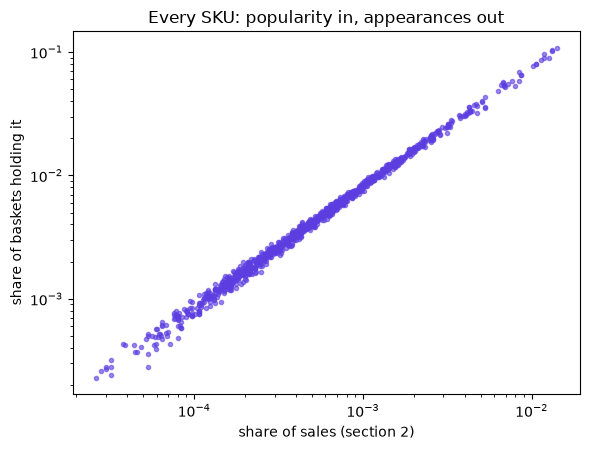

1000 of 1000 SKUs appear in at least one of 100,000 baskets
the most common SKU is in 10.8% of baskets, the rarest that appears in 0.0230%


In [42]:
appears = pd.Series([name for basket in baskets for name in set(basket)]).value_counts() / len(baskets)
df = pd.DataFrame({"share": shares, "appears_in": appears.reindex(names).fillna(0).values}, index=names)

fig, ax = plt.subplots(figsize=(6, 4.6))
ax.loglog(df["share"], df["appears_in"], ".", color="#5b3de0", alpha=0.6)
ax.set_xlabel("share of sales (section 2)")
ax.set_ylabel("share of baskets holding it")
ax.set_title("Every SKU: popularity in, appearances out")
plt.tight_layout()
plt.show()

print(f"{(df['appears_in'] > 0).sum()} of {len(df)} SKUs appear in at least one of 100,000 baskets")
print(f"the most common SKU is in {df['appears_in'].max():.1%} of baskets, the rarest that appears in {df.loc[df['appears_in'] > 0, 'appears_in'].min():.4%}")

In [43]:
found = frequent_itemsets(baskets, min_support=0.005, max_size=2)
pairs = {itemset: support for itemset, support in found.items() if len(itemset) == 2}
print(f"{len(pairs)} pairs are in at least 0.5% of baskets, with nothing planted\n")

for itemset, support in sorted(pairs.items(), key=lambda kv: -kv[1])[:6]:
    print(f"  {support:.2%}   {' + '.join(sorted(itemset))}")

153 pairs are in at least 0.5% of baskets, with nothing planted

  1.31%   Onion 1 kg + Potato 1 kg
  1.23%   Potato 1 kg + Tomato 1 kg
  1.22%   Onion 1 kg + Tomato 1 kg
  1.12%   Coriander Leaves bunch + Onion 1 kg
  1.09%   Surya Grains Toor Dal 1 kg + Tomato 1 kg
  1.09%   Potato 1 kg + Surya Grains Toor Dal 1 kg


In [44]:
lifts = []
for itemset, support in pairs.items():
    a, b = tuple(itemset)
    lifts.append(support / (found[frozenset([a])] * found[frozenset([b])]))
lifts = np.array(lifts)

print(f"lift of the {len(lifts)} accidental pairs: smallest {lifts.min():.2f}, median {np.median(lifts):.2f}, largest {lifts.max():.2f}")

lift of the 153 accidental pairs: smallest 1.01, median 1.12, largest 1.21


In [45]:
size_of = np.array([len(set(b)) for b in baskets])
same_size = [b for b, k in zip(baskets, size_of) if k == 8]
print(f"{len(same_size):,} baskets with exactly 8 different items\n")

found8 = frequent_itemsets(same_size, min_support=0.005, max_size=2)
lifts8 = np.array([s / (found8[frozenset([a])] * found8[frozenset([b])])
                   for itemset, s in found8.items() if len(itemset) == 2
                   for a, b in [tuple(itemset)]])
print(f"lift of the {len(lifts8)} pairs in same-size baskets: median {np.median(lifts8):.2f}, "
      f"smallest {lifts8.min():.2f}, largest {lifts8.max():.2f}")

9,945 baskets with exactly 8 different items

lift of the 96 pairs in same-size baskets: median 0.96, smallest 0.71, largest 1.36


In [46]:
for mean_size in (4, 8, 16):
    sample = background_baskets(20_000, catalog, shares, seed=2, mean_size=mean_size)
    pairs_found = frequent_itemsets(sample, min_support=0.005, max_size=2)
    n_pairs = sum(len(k) == 2 for k in pairs_found)
    print(f"mean {mean_size:>2} products per basket: {n_pairs:>5} pairs at 0.5% support, by accident")

mean  4 products per basket:     0 pairs at 0.5% support, by accident
mean  8 products per basket:   156 pairs at 0.5% support, by accident
mean 16 products per basket:  2825 pairs at 0.5% support, by accident


In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from thilimarketbasket.generate import (
    Planted, make_catalog, popularity, background_baskets, find_items, support_of, plant_itemset as reference_plant)
from thilimarketbasket.mine import frequent_itemsets

catalog = make_catalog()
shares = popularity(catalog)
index = {item.name: i for i, item in enumerate(catalog)}
baskets = background_baskets(100_000, catalog, shares, seed=0)
print(f"{len(baskets):,} background baskets")

100,000 background baskets


In [48]:
for product in ("Tea Powder", "Sugar"):
    print(product)
    for item in find_items(catalog, product)[:5]:
        print(f"   {item.name:36} share of sales {shares[index[item.name]]:.2%}")
    print()

Tea Powder
   Chai Chaska Tea Powder 250 g         share of sales 0.51%
   Chai Chaska Tea Powder 500 g         share of sales 0.40%
   Chai Chaska Tea Powder 1 kg          share of sales 0.15%
   Kaapi Kingdom Tea Powder 250 g       share of sales 0.32%
   Kaapi Kingdom Tea Powder 500 g       share of sales 0.25%

Sugar
   Chai Chaska Sugar 1 kg               share of sales 0.69%
   Chai Chaska Sugar 5 kg               share of sales 0.23%
   Kaapi Kingdom Sugar 1 kg             share of sales 0.43%
   Kaapi Kingdom Sugar 5 kg             share of sales 0.14%
   Sip Sagar Sugar 1 kg                 share of sales 0.26%



In [49]:
best = lambda product: max(find_items(catalog, product), key=lambda item: shares[index[item.name]])
tea, sugar = best("Tea Powder"), best("Sugar")

pair = Planted(items=(tea.name, sugar.name), support=0.02, kind="natural")
print(pair)

Planted(items=('Chai Chaska Tea Powder 250 g', 'Chai Chaska Sugar 1 kg'), support=0.02, kind='natural')


In [50]:
for name in pair.items:
    print(f"{name:32} in {support_of(baskets, [name]):.2%} of baskets")
print(f"{'both together':32} in {support_of(baskets, pair.items):.2%} of baskets (by chance)")

Chai Chaska Tea Powder 250 g     in 3.95% of baskets
Chai Chaska Sugar 1 kg           in 5.31% of baskets
both together                    in 0.24% of baskets (by chance)


In [51]:
wanted = set(pair.items)
rng = np.random.default_rng(1)

target = round(pair.support * len(baskets))
holds = np.array([wanted <= set(basket) for basket in baskets])
already = int(holds.sum())
print(f"target {target:,} baskets; {already:,} already hold the pair; {target - already:,} to add")

picked = rng.choice(np.flatnonzero(~holds), size=target - already, replace=False)
print("first five baskets chosen:", sorted(picked[:5]))

target 2,000 baskets; 237 already hold the pair; 1,763 to add
first five baskets chosen: [np.int64(24360), np.int64(37458), np.int64(67096), np.int64(73233), np.int64(98191)]


In [52]:
product_of = {item.name: (item.category, item.base) for item in catalog}
planted_products = {product_of[name] for name in pair.items}

def clash(basket):
    return [name for name in basket if name not in wanted and product_of[name] in planted_products]

example = next(i for i in picked if clash(baskets[i]))
print("BEFORE:", baskets[example])

BEFORE: ['Chatpata Dosa Batter 1 kg', 'Sip Sagar Coffee Powder 50 g', 'Kaveri Valley Wheat Flour (Atta) 1 kg', 'Amrit Pey Sugar 1 kg', 'Amrit Pey Sugar 1 kg', 'Kaveri Valley Rice Flour 5 kg', 'Amrit Pey Sugar 1 kg', 'Golden Drop Ghee 1 kg', 'Golden Drop Ghee 1 kg', 'Green Chilli 500 g', 'Amrit Pey Sugar 1 kg', 'Banana dozen']


In [53]:
quantity_probs = (0.80, 0.14, 0.04, 0.02)

def rewrite(basket, rng):
    kept = [name for name in basket if name in wanted or product_of[name] not in planted_products]
    have = set(kept)
    added = [name for name in pair.items if name not in have
             for _ in range(1 + rng.choice(len(quantity_probs), p=quantity_probs))]
    new = kept + added
    return [new[j] for j in rng.permutation(len(new))]

after = rewrite(baskets[example], np.random.default_rng(0))
print("AFTER: ", after)
print("\nswapped out:", clash(baskets[example]))

AFTER:  ['Chai Chaska Sugar 1 kg', 'Kaveri Valley Wheat Flour (Atta) 1 kg', 'Banana dozen', 'Golden Drop Ghee 1 kg', 'Golden Drop Ghee 1 kg', 'Sip Sagar Coffee Powder 50 g', 'Chatpata Dosa Batter 1 kg', 'Kaveri Valley Rice Flour 5 kg', 'Green Chilli 500 g', 'Chai Chaska Tea Powder 250 g']

swapped out: ['Amrit Pey Sugar 1 kg', 'Amrit Pey Sugar 1 kg', 'Amrit Pey Sugar 1 kg', 'Amrit Pey Sugar 1 kg']


In [54]:
def my_plant_itemset(baskets, planted, catalog, seed=0, quantity_probs=(0.80, 0.14, 0.04, 0.02)):
    items = list(planted.items)
    product_of = {item.name: (item.category, item.base) for item in catalog}

    unknown = [name for name in items if name not in product_of]
    if unknown:
        raise ValueError(f"not in the catalogue: {unknown}")
    if len({product_of[name] for name in items}) != len(items):
        raise ValueError("a planted itemset needs different products: two of these are the same item or product")
    if not 0 < planted.support < 1:
        raise ValueError(f"support must be between 0 and 1, got {planted.support}")

    rng = np.random.default_rng(seed)
    wanted, planted_products = set(items), {product_of[name] for name in items}
    target = round(planted.support * len(baskets))
    holds = np.array([wanted <= set(basket) for basket in baskets])
    already = int(holds.sum())
    if already > target:
        raise ValueError(f"{already} baskets already hold this itemset by chance, more than the {target} asked for: "
                         f"it is too common to plant at support {planted.support}")
    picked = rng.choice(np.flatnonzero(~holds), size=target - already, replace=False)

    out = list(baskets)
    for i in picked:
        kept = [name for name in out[i] if name in wanted or product_of[name] not in planted_products]
        have = set(kept)
        added = [name for name in items if name not in have
                 for _ in range(1 + rng.choice(len(quantity_probs), p=quantity_probs))]
        new = kept + added
        out[i] = [new[j] for j in rng.permutation(len(new))]
    return out


planted_baskets = my_plant_itemset(baskets, pair, catalog, seed=1)

print(f"target:   {round(pair.support * len(baskets)):,} baskets")
print(f"achieved: {round(support_of(planted_baskets, pair.items) * len(baskets)):,} baskets "
      f"({support_of(planted_baskets, pair.items):.4%})")
print(f"input list left untouched (still {support_of(baskets, pair.items):.2%}):", support_of(baskets, pair.items) < 0.01)

target:   2,000 baskets
achieved: 2,000 baskets (2.0000%)
input list left untouched (still 0.24%): True


In [55]:
reference_baskets = reference_plant(baskets, pair, catalog, seed=1)
print("identical to the reference:", planted_baskets == reference_baskets)
print("baskets that changed:", sum(a != b for a, b in zip(baskets, planted_baskets)))

identical to the reference: True
baskets that changed: 1763


In [56]:
def stats(data):
    a, b = (support_of(data, [name]) for name in pair.items)
    both = support_of(data, pair.items)
    return {"Tea alone": a, "Sugar alone": b, "both": both, "lift": both / (a * b)}

table = pd.DataFrame({"before": stats(baskets), "after": stats(planted_baskets)})
table["before"] = table["before"].map(lambda v: f"{v:.2%}" if v < 1 else f"{v:.2f}")
table["after"] = table["after"].map(lambda v: f"{v:.2%}" if v < 1 else f"{v:.2f}")
table.loc["lift"] = [f"{stats(baskets)['lift']:.2f}", f"{stats(planted_baskets)['lift']:.2f}"]
table

,before,after
Tea alone,3.95%,5.64%
Sugar alone,5.31%,6.99%
both,0.24%,2.00%
lift,1.13,5.08


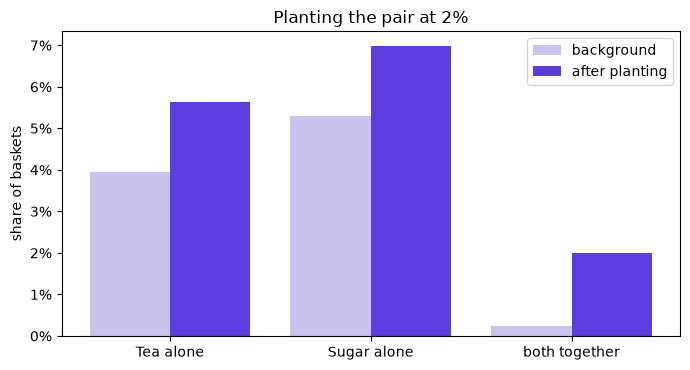

In [57]:
labels = ["Tea alone", "Sugar alone", "both together"]
before = [stats(baskets)[k] for k in ("Tea alone", "Sugar alone", "both")]
after = [stats(planted_baskets)[k] for k in ("Tea alone", "Sugar alone", "both")]

x = np.arange(3)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(x - 0.2, before, 0.4, label="background", color="#c9c3ee")
ax.bar(x + 0.2, after, 0.4, label="after planting", color="#5b3de0")
ax.set_xticks(x, labels)
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.set_ylabel("share of baskets")
ax.legend()
ax.set_title("Planting the pair at 2%")
plt.tight_layout()
plt.show()

In [58]:
def with_pair(data):
    found = frequent_itemsets(data, min_support=0.001, max_size=3)
    return {itemset: s for itemset, s in found.items() if wanted <= itemset}

before_found, after_found = with_pair(baskets), with_pair(planted_baskets)

print(f"itemsets holding both tea and sugar, at 0.1% support:")
print(f"   before planting: {len(before_found)}")
print(f"   after planting:  {len(after_found)}")
print("\nin the planted data:")
for itemset, s in sorted(after_found.items(), key=lambda kv: -kv[1])[:6]:
    extra = sorted(itemset - wanted)
    print(f"   {s:.2%}   tea + sugar" + (f" + {extra[0]}" if extra else "   (the planted pair itself)"))

itemsets holding both tea and sugar, at 0.1% support:
   before planting: 1
   after planting:  21

in the planted data:
   2.00%   tea + sugar   (the planted pair itself)
   0.22%   tea + sugar + Potato 1 kg
   0.22%   tea + sugar + Onion 1 kg
   0.21%   tea + sugar + Tomato 1 kg
   0.20%   tea + sugar + Gokul Fresh Milk 500 ml
   0.19%   tea + sugar + Coriander Leaves bunch


In [59]:
tests = {
    "too common by chance (Onion + Potato at 0.5%)": Planted(("Onion 1 kg", "Potato 1 kg"), 0.005),
    "two SKUs of the same product": Planted(("Chai Chaska Tea Powder 250 g", "Chai Chaska Tea Powder 500 g"), 0.01),
    "an item the shop does not sell": Planted(("Chai Chaska Tea Powder 250 g", "Unicorn Milk 1 L"), 0.01),
    "support out of range": Planted((tea.name, sugar.name), 1.5),
}
for label, bad in tests.items():
    try:
        my_plant_itemset(baskets, bad, catalog)
    except ValueError as error:
        print(f"{label}\n    ValueError: {error}\n")

too common by chance (Onion + Potato at 0.5%)
    ValueError: 1309 baskets already hold this itemset by chance, more than the 500 asked for: it is too common to plant at support 0.005

two SKUs of the same product
    ValueError: a planted itemset needs different products: two of these are the same item or product

an item the shop does not sell
    ValueError: not in the catalogue: ['Unicorn Milk 1 L']

support out of range
    ValueError: support must be between 0 and 1, got 1.5



In [60]:
rare = sorted(catalog, key=lambda item: shares[index[item.name]])
triple_items = []
seen_products = set()
for item in rare:
    if item.category in ("Personal Care", "Spices", "Beverages") and (item.category, item.base) not in seen_products:
        triple_items.append(item.name)
        seen_products.add((item.category, item.base))
    if len(triple_items) == 3:
        break

triple = Planted(tuple(triple_items), 0.0005, kind="surprising")
result = my_plant_itemset(baskets, triple, catalog, seed=2)

print(triple_items)
print(f"chance count before: {round(support_of(baskets, triple.items) * len(baskets))}; "
      f"after planting: {round(support_of(result, triple.items) * len(baskets))} baskets")

['Tulsi Tara Hair Oil 500 ml', 'Tulsi Tara Talcum Powder 200 g', 'Tadka Tales Rasam Powder 200 g']
chance count before: 0; after planting: 50 baskets


In [61]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from thilimarketbasket.generate import (
    NATURAL, SUPPORTS, Planted, make_catalog, popularity, background_baskets, default_planted,
    plant_all as reference_plant_all, plant_itemset, planted_report as reference_report, support_of)

catalog = make_catalog()
shares = popularity(catalog)
baskets = background_baskets(100_000, catalog, shares, seed=0)
product_of = {item.name: item.base for item in catalog}
print(f"{len(baskets):,} background baskets")

100,000 background baskets


In [62]:
for size, groups in NATURAL.items():
    print(f"size {size}:")
    for group in groups:
        print("    ", " + ".join(group))
print("\nsupports:", [f"{s:.2%}" for s in SUPPORTS])

size 2:
     Tea Powder + Sugar
     Bread + Butter
     Toothpaste + Toothbrush
     Detergent Powder + Dishwash Bar
size 3:
     Toor Dal + Sona Masoori Rice + Sunflower Oil
     Turmeric Powder + Red Chilli Powder + Coriander Powder
     Milk + Bread + Eggs
     Shampoo Sachet + Soap Bar + Hair Oil
size 4:
     Wheat Flour (Atta) + Sugar + Salt + Sunflower Oil
     Tea Powder + Milk + Glucose Biscuits + Rusk
     Instant Noodles + Potato Chips + Soft Drink + Namkeen Mixture
     Dosa Batter + Coconut Oil + Curry Leaves + Mustard Seeds
size 5:
     Onion + Tomato + Green Chilli + Ginger + Garlic
     Basmati Rice + Biryani Masala + Ghee + Onion + Curd
     Cornflakes + Milk + Banana + Jam + Bread
     Detergent Bar + Phenyl + Floor Cleaner + Toilet Cleaner + Garbage Bags

supports: ['5.00%', '1.00%', '0.20%', '0.05%']


In [63]:
planted = default_planted(catalog, shares, baskets, seed=0)

plan = pd.DataFrame([{"support": p.support, "size": len(p.items), "kind": p.kind,
                      "items": " + ".join(p.items)} for p in planted])
print(len(plan), "itemsets\n")
plan.groupby(["support", "kind"]).size().unstack()

32 itemsets



kind,natural,surprising
support,,
0.0005,4,4
0.0020,4,4
0.0100,4,4
0.0500,4,4


In [64]:
pd.set_option("display.max_colwidth", 110)
plan[(plan["support"] == 0.01)].reset_index(drop=True)[["size", "kind", "items"]]

,size,kind,items
0,2,natural,Shuddh Detergent Powder 500 g + Ghar Ghar Dishwash Bar 1 bar
1,2,surprising,Rasoi Royale Biryani Masala 100 g + Rupa Rani Toothbrush 1 brush
2,3,natural,Amulya Milk 500 ml + Crunchy Crust Bread 400 g + Gokul Fresh Eggs 6 pack
3,3,surprising,Brinjal 1 kg + Chai Chaska Soft Drink 2 L + Kesari Cumin Seeds 200 g
4,4,natural,Brew Bazaar Tea Powder 250 g + Amulya Milk 500 ml + Crunchy Crust Glucose Biscuits 400 g + Baker's Basket ...
5,4,surprising,Munch Mela Potato Chips Rs 5 pack + Kesari Chaat Masala sachet 10 g + Rupa Rani Deodorant 100 ml + Surya G...
6,5,natural,Annadata Basmati Rice 5 kg + Rasoi Royale Biryani Masala 100 g + Suryamukhi Ghee 200 g + Onion 1 kg + Nand...
7,5,surprising,Pragati Urad Dal 500 g + Shuddh Toilet Cleaner 500 ml + Gokul Fresh Butter 500 g + Suryamukhi Ghee 200 g +...


In [65]:
def check_plan(planted, background=None):
    """Problems with a plan, as a list of strings. Empty means every rule holds."""
    problems = []

    one_sku = {}                                           # rule 1
    for p in planted:
        for name in p.items:
            if one_sku.setdefault(product_of[name], name) != name:
                problems.append(f"{product_of[name]} appears as both {one_sku[product_of[name]]} and {name}")

    sets = [set(p.items) for p in planted]                 # rule 2
    for i, a in enumerate(sets):
        for j, b in enumerate(sets):
            if i != j and a <= b:
                problems.append(f"{planted[i].items} is contained in {planted[j].items}")

    if background is not None:                             # rule 3
        held_by = {}
        for number, basket in enumerate(background):
            for name in set(basket):
                held_by.setdefault(name, set()).add(number)
        for p in planted:
            chance = len(set.intersection(*(held_by.get(name, set()) for name in p.items))) / len(background)
            if chance > 0.3 * p.support:
                problems.append(f"{p.items}: chance gives {chance:.3%}, over 30% of {p.support:.2%}")
    return problems


print("the plan:", check_plan(planted, baskets) or "no problems")

the plan: no problems


In [66]:
tea = next(p for p in planted if any(product_of[n] == "Tea Powder" for n in p.items))
other_tea = next(i.name for i in catalog if i.base == "Tea Powder" and i.name not in tea.items)
wrong_item = tuple(other_tea if product_of[n] == "Tea Powder" else n for n in tea.items)

for problem in check_plan(planted + [Planted(wrong_item, 0.01, "natural")]):
    print("-", problem)

- Tea Powder appears as both Brew Bazaar Tea Powder 250 g and Chai Chaska Tea Powder 250 g


In [67]:
from collections import Counter

uses = Counter(name for p in planted for name in p.items)
shared = {name: n for name, n in uses.items() if n > 1}
print(f"{len(uses)} distinct items across {len(planted)} itemsets; {len(shared)} of them are in more than one")
print("\nthe most shared:")
for name, n in uses.most_common(4):
    print(f"   {n} itemsets  {name}")

79 distinct items across 32 itemsets; 24 of them are in more than one

the most shared:
   4 itemsets  Crunchy Crust Bread 400 g
   4 itemsets  Shuddh Toilet Cleaner 500 ml
   3 itemsets  Brew Bazaar Tea Powder 250 g
   3 itemsets  Rasoi Royale Biryani Masala 100 g


In [68]:
def my_plant_all(baskets, planted, catalog, seed=0):
    problems = check_plan(planted)
    if problems:
        raise ValueError("; ".join(problems))
    order = sorted(range(len(planted)), key=lambda i: (-len(planted[i].items), -planted[i].support))
    out = list(baskets)
    for step, i in enumerate(order):
        out = plant_itemset(out, planted[i], catalog, seed=seed + step, allow_excess=True)
    return out


mine = my_plant_all(baskets, planted, catalog, seed=0)
print("identical to the reference:", mine == reference_plant_all(baskets, planted, catalog, seed=0))

identical to the reference: True


In [69]:
def my_report(baskets, planted):
    rows = []
    for p in planted:
        held = sum(set(p.items) <= set(basket) for basket in baskets)
        rows.append({"kind": p.kind, "size": len(p.items), "target": p.support,
                     "realised": held / len(baskets), "items": " + ".join(p.items)})
    return pd.DataFrame(rows)

report = my_report(mine, planted)
report["off_by"] = report["realised"] / report["target"] - 1

exact = (report["off_by"].abs() < 0.01).sum()
print(f"{exact} of {len(report)} itemsets are within 1% of their target\n")
report.loc[report["off_by"].abs() >= 0.01, ["kind", "size", "target", "realised", "off_by", "items"]]


29 of 32 itemsets are within 1% of their target



,kind,size,target,realised,off_by,items
0,natural,2,0.050,0.05086,0.0172,Crunchy Crust Bread 400 g + Gokul Fresh Butter 500 g
10,natural,3,0.010,0.01011,0.0110,Amulya Milk 500 ml + Crunchy Crust Bread 400 g + Gokul Fresh Eggs 6 pack
16,natural,2,0.002,0.00664,2.3200,Brew Bazaar Tea Powder 250 g + Chai Chaska Sugar 1 kg


In [70]:
worst = report["off_by"].idxmax()
pair = planted[worst]
print("the worst:", pair.items, f"target {pair.support:.2%}\n")

for other in planted:
    shared_items = set(pair.items) & set(other.items)
    if other is not pair and shared_items:
        print(f"  shares {sorted(shared_items)[0]!r:36} with a {other.support:.2%} {other.kind} set of {len(other.items)}")

the worst: ('Brew Bazaar Tea Powder 250 g', 'Chai Chaska Sugar 1 kg') target 0.20%

  shares 'Brew Bazaar Tea Powder 250 g'       with a 5.00% surprising set of 3
  shares 'Chai Chaska Sugar 1 kg'             with a 5.00% natural set of 4
  shares 'Brew Bazaar Tea Powder 250 g'       with a 1.00% natural set of 4


In [71]:
a = next(p for p in planted if pair.items[0] in p.items and p.support == 0.05)
b = next(p for p in planted if pair.items[1] in p.items and p.support == 0.05)
both = support_of(mine, set(a.items) | set(b.items))
print(f"baskets holding the whole 5% triple AND the whole 5% four-set: {both:.3%}")
print(f"each is in 5% of baskets, so if independent: {0.05 * 0.05:.3%}")

baskets holding the whole 5% triple AND the whole 5% four-set: 0.269%
each is in 5% of baskets, so if independent: 0.250%


In [72]:
def plant_in_order(order):
    out = list(baskets)
    for step, i in enumerate(order):
        out = plant_itemset(out, planted[i], catalog, seed=step, allow_excess=True)
    r = my_report(out, planted)
    off = r["realised"] / r["target"] - 1
    return {"misses (>1% off)": int((off.abs() > 0.01).sum()), "worst overshoot": f"{off.max():+.0%}"}

orders = {
    "large first (ours)": sorted(range(len(planted)), key=lambda i: (-len(planted[i].items), -planted[i].support)),
    "rarest first": sorted(range(len(planted)), key=lambda i: (planted[i].support, len(planted[i].items))),
    "as listed": list(range(len(planted))),
}
pd.DataFrame({name: plant_in_order(order) for name, order in orders.items()}).T

,misses (>1% off),worst overshoot
large first (ours),3,+232%
rarest first,6,+290%
as listed,3,+225%


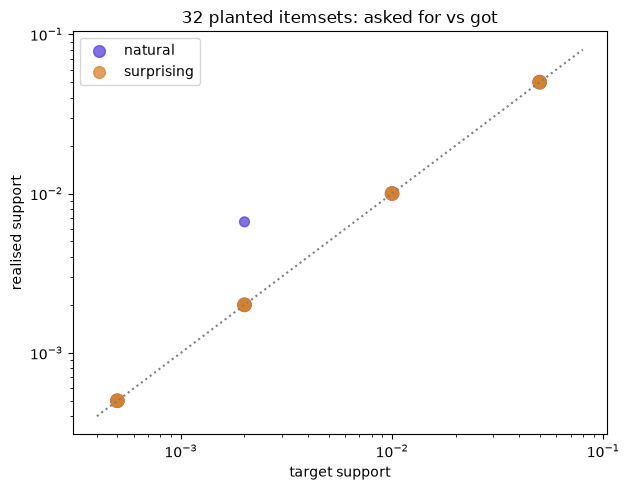

In [73]:
fig, ax = plt.subplots(figsize=(6.4, 5))
colors = {"natural": "#5b3de0", "surprising": "#d9822b"}
for kind, group in report.groupby("kind"):
    ax.scatter(group["target"], group["realised"], s=22 + 14 * group["size"], color=colors[kind], alpha=0.75, label=kind)
low, high = 0.0004, 0.08
ax.plot([low, high], [low, high], color="grey", linestyle=":")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("target support"); ax.set_ylabel("realised support")
ax.set_title("32 planted itemsets: asked for vs got")
ax.legend()
plt.tight_layout()
plt.show()

In [74]:
touched = np.mean([a != b for a, b in zip(baskets, mine)])
counts = pd.Series([sum(name in {n for p in planted for n in p.items} for name in set(basket)) for basket in mine])

print(f"{touched:.0%} of the baskets were rewritten by planting")
print(f"{(counts == 0).mean():.0%} of baskets hold no planted item at all")
print(f"on average a basket holds {counts.mean():.1f} of the 79 planted items (it held {np.mean([sum(name in {n for p in planted for n in p.items} for name in set(b)) for b in baskets]):.1f} before)")

40% of the baskets were rewritten by planting
16% of baskets hold no planted item at all
on average a basket holds 3.1 of the 79 planted items (it held 1.4 before)


In [81]:
for seed in range(5):
    try:
        plan_s = default_planted(catalog, shares, baskets, seed=seed)
    except ValueError as error:
        print(f"seed {seed}: no valid plan ({error})")
        continue
    result = my_report(reference_plant_all(baskets, plan_s, catalog, seed=seed), plan_s)
    off = result["realised"] / result["target"] - 1
    print(f"seed {seed}: {int((off.abs() > 0.01).sum()):>2} of 32 more than 1% off, worst overshoot {off.max():+.0%}")

seed 0:  3 of 32 more than 1% off, worst overshoot +232%
seed 1:  0 of 32 more than 1% off, worst overshoot +0%
seed 2:  2 of 32 more than 1% off, worst overshoot +29%
seed 3: no valid plan (the natural set ('Shuddh Detergent Powder 500 g', 'Sparkle Home Dishwash Bar pack of 3') is too common by chance, or overlaps another, at support 0.002)
seed 4:  0 of 32 more than 1% off, worst overshoot +0%


In [82]:
import math
import time
from collections import Counter
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from thilimarketbasket.dataset import generate_dataset, classify_itemset
from thilimarketbasket.mine import frequent_itemsets as reference_miner, rules

data = generate_dataset(n_baskets=100_000, seed=0)     # sections 1 to 5, in one call (about 10 seconds)
baskets = data.baskets
print(f"{len(baskets):,} baskets, {len(data.planted)} planted itemsets")

100,000 baskets, 32 planted itemsets


In [83]:
toy = [
    ["tea", "sugar", "milk"], ["tea", "sugar"], ["bread", "butter", "milk"],
    ["tea", "milk"], ["bread", "butter"], ["tea", "sugar", "bread"],
]
toy_items = sorted({item for basket in toy for item in basket})

print(f"{len(toy_items)} items. Itemsets of every size a brute-force miner would look at: "
      f"{sum(math.comb(len(toy_items), k) for k in range(1, len(toy_items) + 1))}")

5 items. Itemsets of every size a brute-force miner would look at: 31


In [84]:
def plain_apriori(baskets, min_support, max_size=5):
    n = len(baskets)
    min_count = max(1, math.ceil(min_support * n - 1e-9))     # the allowance guards 0.0005 * 100000
    basket_sets = [frozenset(basket) for basket in baskets]   # quantity does not matter: two milks count as milk

    counts = Counter(item for basket in basket_sets for item in basket)
    level = {frozenset([item]): c for item, c in counts.items() if c >= min_count}
    found = dict(level)

    size = 1
    while level and size < max_size:
        candidates = set()
        for a, b in combinations(level, 2):                   # JOIN
            union = a | b
            if len(union) == size + 1 and all(union - {x} in level for x in union):   # PRUNE
                candidates.add(union)
        counts = Counter()
        for basket in basket_sets:                            # COUNT
            for candidate in candidates:
                if candidate <= basket:
                    counts[candidate] += 1
        level = {c: k for c, k in counts.items() if k >= min_count}
        found.update(level)
        size += 1
    return {itemset: count / n for itemset, count in found.items()}


for itemset, support in sorted(plain_apriori(toy, 0.5).items(), key=lambda kv: (len(kv[0]), sorted(kv[0]))):
    print(f"{support:.2f}  {' + '.join(sorted(itemset))}")

0.50  bread
0.50  milk
0.50  sugar
0.67  tea
0.50  sugar + tea


In [85]:
sample = baskets[:2000]

start = time.time()
slow = plain_apriori(sample, 0.01)
print(f"plain Apriori: {len(slow)} frequent itemsets in {time.time() - start:.1f} s")
print("by size:", dict(sorted(Counter(len(s) for s in slow).items())))

plain Apriori: 471 frequent itemsets in 6.6 s
by size: {1: 243, 2: 168, 3: 45, 4: 13, 5: 2}


In [86]:
bits = {item: sum(1 << number for number, basket in enumerate(toy) if item in basket) for item in toy_items}

for item, value in bits.items():
    print(f"{item:7} {value:06b}")

both = bits["tea"] & bits["sugar"]
print(f"\ntea AND sugar = {both:06b}   -> {both.bit_count()} baskets hold both")

bread   110100
butter  010100
milk    001101
sugar   100011
tea     101011

tea AND sugar = 100011   -> 3 baskets hold both


In [87]:
def bitsets(baskets):
    """One big integer per item: bit i is 1 when basket i holds the item."""
    numbers_of = {}
    for number, basket in enumerate(baskets):
        for item in set(basket):
            numbers_of.setdefault(item, []).append(number)
    result = {}
    for item, numbers in numbers_of.items():
        held = np.zeros(len(baskets), dtype=bool)
        held[numbers] = True
        result[item] = int.from_bytes(np.packbits(held).tobytes(), "big")
    return result


def my_frequent_itemsets(baskets, min_support, max_size=5):
    n = len(baskets)
    min_count = max(1, math.ceil(min_support * n - 1e-9))
    bits = bitsets(baskets)

    level = {(item,): value for item, value in bits.items() if value.bit_count() >= min_count}
    found = {frozenset(items): value.bit_count() / n for items, value in level.items()}

    size = 1
    while level and size < max_size:
        by_prefix = {}                                    # itemsets that agree on all but their last item
        for items in sorted(level):
            by_prefix.setdefault(items[:-1], []).append(items[-1])
        next_level = {}
        for prefix, lasts in by_prefix.items():
            for a, b in combinations(lasts, 2):           # JOIN: a < b because `lasts` is sorted
                candidate = prefix + (a, b)
                if any(candidate[:i] + candidate[i + 1:] not in level for i in range(len(candidate) - 2)):
                    continue                              # PRUNE
                held = level[prefix + (a,)] & bits[b]     # COUNT: one AND
                if held.bit_count() >= min_count:
                    next_level[candidate] = held
        level = next_level
        found.update({frozenset(items): value.bit_count() / n for items, value in level.items()})
        size += 1
    return found


print("toy example matches plain Apriori:", my_frequent_itemsets(toy, 0.5) == plain_apriori(toy, 0.5))

start = time.time()
fast = my_frequent_itemsets(sample, 0.01)
print(f"bitset Apriori on the same 2,000 baskets: {time.time() - start:.3f} s, same answer as plain: {fast == slow}")

toy example matches plain Apriori: True
bitset Apriori on the same 2,000 baskets: 0.043 s, same answer as plain: True


In [88]:
start = time.time()
truth = my_frequent_itemsets(baskets, min_support=0.0005, max_size=5)
print(f"{len(truth):,} frequent itemsets in {time.time() - start:.1f} s")

print("identical to the reference miner:", truth == reference_miner(baskets, 0.0005, 5))
print("identical to the dataset's truth: ", truth == data.truth)

56,470 frequent itemsets in 10.5 s
identical to the reference miner: True
identical to the dataset's truth:  True


In [89]:
by_size = pd.Series(Counter(len(itemset) for itemset in truth)).sort_index()
print(by_size.rename("itemsets").to_frame().T.to_string(index=False))

  1     2     3     4    5
977 18237 16528 13052 7676


In [90]:
rows = []
for min_support in (0.01, 0.005, 0.002, 0.001, 0.0005):
    start = time.time()
    found = my_frequent_itemsets(baskets, min_support, 5)
    rows.append({"min support": f"{min_support:.2%}", "min baskets": round(min_support * len(baskets)),
                 "itemsets": len(found), "seconds": round(time.time() - start, 1)})
pd.DataFrame(rows)

,min support,min baskets,itemsets,seconds
0,1.00%,1000,491,0.6
1,0.50%,500,1747,1.3
2,0.20%,200,8317,3.0
3,0.10%,100,19766,5.3
4,0.05%,50,56470,10.6


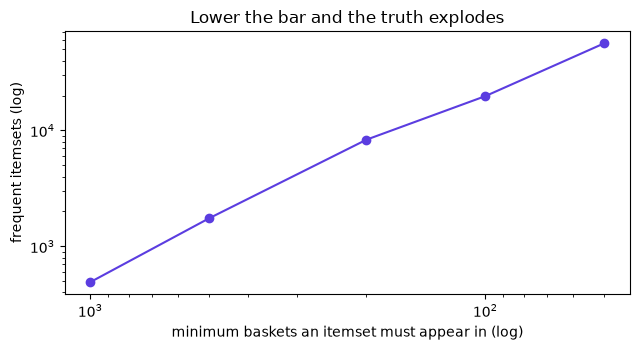

In [91]:
counts = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(counts["min baskets"], counts["itemsets"], "o-", color="#5b3de0")
ax.set_xscale("log"); ax.set_yscale("log")
ax.invert_xaxis()
ax.set_xlabel("minimum baskets an itemset must appear in (log)")
ax.set_ylabel("frequent itemsets (log)")
ax.set_title("Lower the bar and the truth explodes")
plt.tight_layout()
plt.show()

In [92]:
def my_classify(itemset, planted):
    if len(itemset) == 1:
        return "single"
    sets = [frozenset(p.items) for p in planted]
    if itemset in sets:
        return "planted"
    if any(itemset < s for s in sets):
        return "part"
    if any(len(itemset & s) >= 2 for s in sets):
        return "extension"
    return "chance"


labels = {itemset: my_classify(itemset, data.planted) for itemset in truth}
print("same labels as the reference for all", f"{len(labels):,}", "itemsets:",
      all(labels[i] == classify_itemset(i, data.planted) for i in truth))

same labels as the reference for all 56,470 itemsets: True


In [93]:
table = pd.DataFrame({"size": [len(i) for i in truth], "label": list(labels.values())})
summary = table["label"].value_counts().reindex(["single", "planted", "part", "extension", "chance"])
print(summary.to_string())
print(f"\nplanted are {summary['planted'] / len(truth):.2%} of the truth")

label
single         977
planted         32
part           303
extension    31902
chance       23256

planted are 0.06% of the truth


label  single  planted  part  extension  chance
size                                           
1         977        0     0          0       0
2           0        8   151          0   18078
3           0        8   112      11231    5177
4           0        8    40      13003       1
5           0        8     0       7668       0


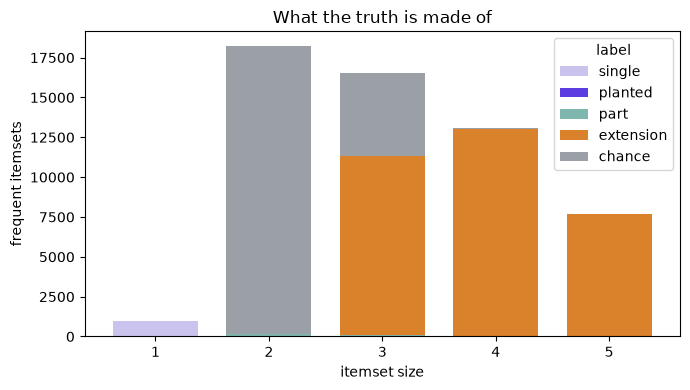

In [94]:
crosstab = pd.crosstab(table["size"], table["label"])[["single", "planted", "part", "extension", "chance"]]
print(crosstab)
colors = ["#c9c3ee", "#5b3de0", "#7fb7ae", "#d9822b", "#9aa0a6"]
ax = crosstab.plot.bar(stacked=True, figsize=(7, 4), color=colors, width=0.75)
ax.set_xlabel("itemset size")
ax.set_ylabel("frequent itemsets")
ax.set_title("What the truth is made of")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [95]:
def example(label, size):
    pool = [(s, i) for i, s in truth.items() if labels[i] == label and len(i) == size]
    support, itemset = max(pool, key=lambda x: x[0])
    return f"{support:.2%}  " + " + ".join(sorted(itemset))

for label, size in (("planted", 3), ("part", 2), ("extension", 3), ("chance", 3)):
    print(f"{label:10}", example(label, size))

planted    5.00%  Brew Bazaar Tea Powder 250 g + Ghar Ghar Floor Cleaner 2 L + Kids Korner Notebook pack of 5
part       6.00%  Onion 1 kg + Tomato 500 g
extension  0.99%  Crunchy Crust Bread 400 g + Onion 1 kg + Tomato 500 g
chance     0.44%  Crunchy Crust Bread 400 g + Golden Drop Sunflower Oil 500 ml + Onion 1 kg


In [96]:
common = {i: s for i, s in truth.items() if s >= 0.005 and len(i) <= 3}
found_rules = rules(common, min_confidence=0.3)

print(f"{len(found_rules)} rules at confidence >= 0.3 from {len(common)} itemsets\n")
for antecedent, consequent, support, confidence, lift in found_rules[:5]:
    print(f"{' + '.join(sorted(antecedent))}  ->  {' + '.join(sorted(consequent))}")
    print(f"     support {support:.2%}, confidence {confidence:.0%}, lift {lift:.1f}   [{labels[antecedent | consequent]}]")

1128 rules at confidence >= 0.3 from 1468 itemsets

Kesari Cumin Seeds 200 g  ->  Brinjal 1 kg + Chai Chaska Soft Drink 2 L
     support 1.00%, confidence 86%, lift 84.6   [planted]
Brinjal 1 kg + Chai Chaska Soft Drink 2 L  ->  Kesari Cumin Seeds 200 g
     support 1.00%, confidence 98%, lift 84.6   [planted]
Kesari Chaat Masala sachet 10 g  ->  Munch Mela Potato Chips Rs 5 pack + Rupa Rani Deodorant 100 ml
     support 1.00%, confidence 85%, lift 84.2   [part]
Munch Mela Potato Chips Rs 5 pack + Rupa Rani Deodorant 100 ml  ->  Kesari Chaat Masala sachet 10 g
     support 1.00%, confidence 99%, lift 84.2   [part]
Kesari Chaat Masala sachet 10 g  ->  Rupa Rani Deodorant 100 ml + Surya Grains Salt 1 kg
     support 1.00%, confidence 85%, lift 82.5   [part]


In [97]:
small = my_frequent_itemsets(baskets, 0.001, max_size=3)
print(f"{len(small):,} itemsets")
print(pd.Series([my_classify(i, data.planted) for i in small]).value_counts().to_string())

13,650 itemsets
chance       8128
extension    4399
single        906
part          205
planted        12


In [98]:
import os
import warnings

os.environ["TRANSFORMERS_VERBOSITY"] = "error"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from transformers import AutoTokenizer

from thilimarketbasket.dataset import generate_dataset
from thilimarketbasket.verbalize import verbalize_basket as reference_verbalize

data = generate_dataset(n_baskets=100_000, seed=0)
baskets = data.baskets
print(f"{len(baskets):,} baskets")
print(baskets[0])

100,000 baskets
['Nandini Pure Curd 500 g', 'Chatpata Potato Chips Rs 5 pack', 'Little Lotus Batteries (AA) pack of 4']


In [99]:
def my_verbalize_basket(items, seed=None, max_items=30):
    different = sorted(set(items))                    # each item once; sorted so a seed gives a repeatable order
    rng = np.random.default_rng(seed)
    order = rng.permutation(len(different))[:max_items]
    return "Basket: " + "; ".join(different[i] for i in order)


for seed in range(3):
    print(my_verbalize_basket(baskets[0], seed=seed))

Basket: Nandini Pure Curd 500 g; Chatpata Potato Chips Rs 5 pack; Little Lotus Batteries (AA) pack of 4
Basket: Chatpata Potato Chips Rs 5 pack; Little Lotus Batteries (AA) pack of 4; Nandini Pure Curd 500 g
Basket: Nandini Pure Curd 500 g; Chatpata Potato Chips Rs 5 pack; Little Lotus Batteries (AA) pack of 4


In [100]:
same_seed = my_verbalize_basket(baskets[0], seed=7) == my_verbalize_basket(list(reversed(baskets[0])), seed=7)
orders = {my_verbalize_basket(baskets[0], seed=s) for s in range(50)}
items_seen = {frozenset(t[len("Basket: "):].split("; ")) for t in orders}

print("a seed gives the same text whatever order the basket arrived in:", same_seed)
print(f"50 seeds gave {len(orders)} different texts, but only {len(items_seen)} different set of items")
print("matches the reference:", all(my_verbalize_basket(b, seed=1) == reference_verbalize(b, seed=1) for b in baskets[:2000]))

a seed gives the same text whatever order the basket arrived in: True
50 seeds gave 6 different texts, but only 1 different set of items
matches the reference: True


In [101]:
def alphabetical_rate(texts):
    later = total = 0
    for text in texts:
        items = text[len("Basket: "):].split("; ")
        for a, b in zip(items, items[1:]):
            later += b > a
            total += 1
    return later / total

sample = baskets[:5000]
fixed = ["Basket: " + "; ".join(sorted(set(b))) for b in sample]
shuffled = [my_verbalize_basket(b, seed=i) for i, b in enumerate(sample)]

print(f"sorted order:   the next item is later in the alphabet {alphabetical_rate(fixed):.0%} of the time")
print(f"shuffled order: {alphabetical_rate(shuffled):.0%}")

sorted order:   the next item is later in the alphabet 100% of the time
shuffled order: 50%


In [102]:
tokenizer = AutoTokenizer.from_pretrained("HuggingFaceTB/SmolLM2-135M")
print(f"vocabulary: {len(tokenizer):,} tokens\n")

for name in ("Onion 1 kg", "Surya Grains Toor Dal 1 kg", "Rasoi Royale Coriander Powder sachet 10 g"):
    print(f"{name}\n   {len(tokenizer.tokenize(name))} tokens: {tokenizer.tokenize(name)}\n")

vocabulary: 49,152 tokens

Onion 1 kg
   5 tokens: ['On', 'ion', 'Ġ', '1', 'Ġkg']

Surya Grains Toor Dal 1 kg
   11 tokens: ['S', 'ury', 'a', 'ĠGra', 'ins', 'ĠTo', 'or', 'ĠDal', 'Ġ', '1', 'Ġkg']

Rasoi Royale Coriander Powder sachet 10 g
   14 tokens: ['R', 'as', 'oi', 'ĠRoy', 'ale', 'ĠCor', 'iander', 'ĠPowder', 'Ġsac', 'het', 'Ġ', '1', '0', 'Ġg']



tokens per basket: mean 108, median 102, 95th percentile 198, 99th 250, longest 356
tokens per item:   about 11.3


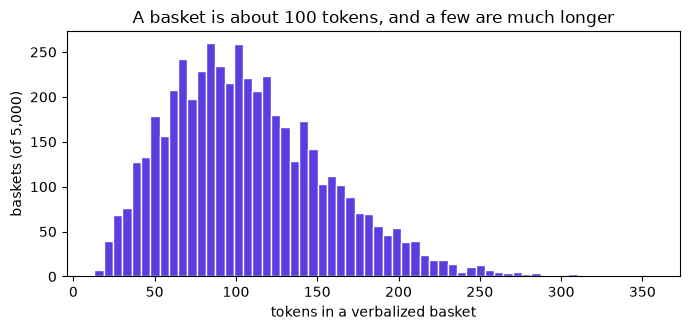

In [103]:
texts = [my_verbalize_basket(b, seed=i) for i, b in enumerate(baskets[:5000])]
lengths = np.array([len(ids) for ids in tokenizer(texts)["input_ids"]])
distinct = np.array([len(set(b)) for b in baskets[:5000]])

print(f"tokens per basket: mean {lengths.mean():.0f}, median {int(np.median(lengths))}, "
      f"95th percentile {int(np.percentile(lengths, 95))}, 99th {int(np.percentile(lengths, 99))}, longest {lengths.max()}")
print(f"tokens per item:   about {lengths.sum() / distinct.sum():.1f}")

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist(lengths, bins=60, color="#5b3de0", edgecolor="white")
ax.set_xlabel("tokens in a verbalized basket")
ax.set_ylabel("baskets (of 5,000)")
ax.set_title("A basket is about 100 tokens, and a few are much longer")
plt.tight_layout()
plt.show()

In [104]:
for cap in (128, 192, 256, 384, 512):
    print(f"context {cap:>3}: cuts {np.mean(lengths > cap):.1%} of baskets")

context 128: cuts 30.1% of baskets
context 192: cuts 6.1% of baskets
context 256: cuts 0.8% of baskets
context 384: cuts 0.0% of baskets
context 512: cuts 0.0% of baskets


In [105]:
rng = np.random.default_rng(0)
is_val = rng.random(len(baskets)) < 0.05
train = [b for b, v in zip(baskets, is_val) if not v]
val = [b for b, v in zip(baskets, is_val) if v]
print(f"{len(train):,} baskets to train on, {len(val):,} held out")

95,002 baskets to train on, 4,998 held out


In [106]:
def length_with(separator, prefix="Basket: "):
    some = [prefix + separator.join(sorted(set(b))) for b in baskets[:2000]]
    return np.mean([len(ids) for ids in tokenizer(some)["input_ids"]])

for label, separator, prefix in (("semicolon (ours)", "; ", "Basket: "), ("comma", ", ", "Basket: "),
                                 ("pipe", " | ", "Basket: "), ("newline", "\n", "Basket:\n"),
                                 ("no prefix", "; ", "")):
    print(f"{label:18} {length_with(separator, prefix):6.1f} tokens per basket")

semicolon (ours)    107.8 tokens per basket
comma               107.8 tokens per basket
pipe                107.8 tokens per basket
newline             110.3 tokens per basket
no prefix           104.9 tokens per basket


In [107]:
import os
import time
import warnings

os.environ["TRANSFORMERS_VERBOSITY"] = "error"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from thilimarketbasket.dataset import generate_dataset
from thilimarketbasket.evaluate import (
    candidate_token_ids, make_cases, popularity_scores, score_candidates)
from thilimarketbasket.verbalize import verbalize_prefix

data = generate_dataset(n_baskets=100_000, seed=0)
names = [item.name for item in data.catalog]
position = {name: i for i, name in enumerate(names)}

# the same split as section 7
is_val = np.random.default_rng(0).random(len(data.baskets)) < 0.05
train = [b for b, v in zip(data.baskets, is_val) if not v]
val = [b for b, v in zip(data.baskets, is_val) if v]
print(f"{len(train):,} training baskets, {len(val):,} held out, {len(names):,} items in the catalogue")

95,002 training baskets, 4,998 held out, 1,000 items in the catalogue


In [108]:
def my_rank_of(scores, target, exclude=()):
    """Rank of `target` (1 is best) among the items not in `exclude`. A tie counts against the target."""
    keep = np.ones(len(scores), dtype=bool)
    keep[list(exclude)] = False
    keep[target] = False                     # compare the target with the others, never with itself
    return 1 + int((scores[keep] >= scores[target]).sum())


def my_summary(ranks):
    ranks = np.asarray(ranks)
    return {"MRR": np.mean(1 / ranks), "hits@1": np.mean(ranks <= 1),
            "hits@10": np.mean(ranks <= 10), "hits@50": np.mean(ranks <= 50), "median rank": np.median(ranks)}


print(my_rank_of(np.array([0.1, 0.9, 0.5, 0.5]), 2))          # 3: one item is better and one ties
print(my_rank_of(np.array([0.1, 0.9, 0.5]), 2, exclude=[1]))   # 1: the better item is not a candidate

3
1


In [109]:
cases = make_cases(val, names, n_cases=200, seed=0)

for case in cases[:3]:
    print("visible:", case["visible"])
    print("hidden: ", case["target"], "\n")

visible: ['Amulya Milk 500 ml', 'Chatpata Banana Chips Rs 5 pack', 'Garlic 1 kg', 'Golden Drop Sunflower Oil 500 ml', 'Kesari Black Pepper 200 g', 'Masala Mantra Red Chilli Powder 100 g', 'Masala Mantra Sambar Powder 100 g', 'Onion 500 g', 'Sundar Sutra Deodorant 150 ml', 'Surya Grains Wheat Flour (Atta) 1 kg', 'Swad Sagar Mustard Seeds sachet 10 g', 'Tomato 500 g']
hidden:  Nandini Pure Eggs 12 pack 

visible: ['Crunch Club Dosa Batter 500 g', 'Dhara Fresh Sunflower Oil 500 ml', 'Glow Garden Hair Oil 100 ml', 'Kaveri Valley Rice Flour 5 kg', 'Kaveri Valley Toor Dal 1 kg', 'Little Lotus Ball Pen pack of 5', 'Munch Mela Potato Chips Rs 5 pack', 'Nandini Pure Milk 500 ml', 'Rasoi Royale Turmeric Powder 100 g', 'Shubham Select Sona Masoori Rice 1 kg']
hidden:  Suryamukhi Coconut Oil 1 L 

visible: ['Chai Chaska Fruit Juice 200 ml', 'Garlic 1 kg', 'Glow Garden Razor pack of 5', 'Glow Garden Shampoo Bottle 180 ml', 'Kaveri Valley Sago (Sabudana) 250 g', 'Kids Korner Notebook pack of 5', 'Ma

In [110]:
n = len(names)
random_mrr = np.mean(1 / np.arange(1, n + 1))
print(f"random ranking: expected MRR {random_mrr:.4f}")

pop = popularity_scores(train, names)
pop_ranks = [my_rank_of(pop, position[c["target"]], [position[v] for v in c["visible"]]) for c in cases]
print("popularity:    ", {k: round(float(v), 3) for k, v in my_summary(pop_ranks).items()})

random ranking: expected MRR 0.0075
popularity:     {'MRR': 0.052, 'hits@1': 0.005, 'hits@10': 0.12, 'hits@50': 0.39, 'median rank': 105.5}


In [4]:
import numpy as np
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
tokenizer = AutoTokenizer.from_pretrained("HuggingFaceTB/SmolLM2-135M")
model = AutoModelForCausalLM.from_pretrained("HuggingFaceTB/SmolLM2-135M").to(device).eval()


@torch.no_grad()
def score_candidates_torch(model, prefix_ids, candidate_ids, batch=250):
    """log P(candidate | prefix) for each candidate, summed over its tokens."""
    start = len(prefix_ids) - 1                      # the position whose output predicts the candidate's first token
    scores = np.zeros(len(candidate_ids))
    order = sorted(range(len(candidate_ids)), key=lambda i: len(candidate_ids[i]))
    for first in range(0, len(order), batch):
        chunk = order[first:first + batch]
        sequences = [list(prefix_ids) + list(candidate_ids[i]) for i in chunk]
        width = max(len(s) for s in sequences)
        ids = torch.zeros(len(chunk), width, dtype=torch.long)
        mask = torch.zeros(len(chunk), width, dtype=torch.long)
        for row, s in enumerate(sequences):
            ids[row, :len(s)] = torch.tensor(s)
            mask[row, :len(s)] = 1
        ids, mask = ids.to(device), mask.to(device)
        logits = model(input_ids=ids, attention_mask=mask).logits[:, start:, :].float()
        logp = torch.log_softmax(logits, dim=-1)     # only the candidate's positions, to save memory
        for row, i in enumerate(chunk):
            cand = candidate_ids[i]
            scores[i] = sum(float(logp[row, k, cand[k]]) for k in range(len(cand)))
    return scores

/opt/conda/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 272/272 [00:00<00:00, 3342.04it/s]


In [1]:
import math
import os
import random
import time
import numpy as np
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer
from thilimarketbasket.dataset import generate_dataset
from thilimarketbasket.verbalize import verbalize_prefix

torch.set_num_threads(min(4, os.cpu_count() or 2))

print("1/4 Generating dataset...", flush=True)
data = generate_dataset(n_baskets=100_000, seed=0)
is_val = np.random.default_rng(0).random(len(data.baskets)) < 0.05
train = [b for b, v in zip(data.baskets, is_val) if not v]

print("2/4 Loading model...", flush=True)
tokenizer = AutoTokenizer.from_pretrained("HuggingFaceTB/SmolLM2-135M")
model = AutoModelForCausalLM.from_pretrained("HuggingFaceTB/SmolLM2-135M", torch_dtype=torch.float32)
model.config.use_cache = False

# Freeze bottom 24 of 30 layers so backward pass is ~5x faster on CPU
for param in model.model.layers[:24].parameters():
    param.requires_grad = False


def encode_baskets(tokenizer, baskets, seeds, max_len=96):
    eos = tokenizer.eos_token or ""
    return [
        tokenizer.encode(verbalize_prefix(b, seed=int(s)) + eos)[:max_len]
        for b, s in zip(baskets, seeds)
    ]


def pad(examples):
    width = max(len(e) for e in examples)
    ids = torch.zeros(len(examples), width, dtype=torch.long)
    mask = torch.zeros(len(examples), width)
    for row, e in enumerate(examples):
        ids[row, :len(e)] = torch.tensor(e)
        mask[row, :len(e)] = 1
    return ids, mask


def next_token_loss_torch(model, ids, mask):
    logits = model(input_ids=ids[:, :-1]).logits
    per_token = torch.nn.functional.cross_entropy(logits.transpose(1, 2), ids[:, 1:], reduction="none")
    real = mask[:, 1:]
    return (per_token * real).sum() / real.sum()


STEPS, BATCH, PEAK, WARMUP = 40, 2, 3e-4, 5
trainable_params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.AdamW(trainable_params, lr=PEAK, weight_decay=0.01)
schedule = lambda step: (step + 1) / WARMUP if step < WARMUP else \
    0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * (step - WARMUP) / (STEPS - WARMUP)))

print(f"3/4 Starting {STEPS} fast CPU steps...", flush=True)
model.train()

for step in range(STEPS):
    step_start = time.time()
    batch = random.sample(train, BATCH)
    ids, mask = pad(encode_baskets(tokenizer, batch, [random.randrange(2**31) for _ in batch]))
    
    for group in optimizer.param_groups:
        group["lr"] = PEAK * schedule(step)
    loss = next_token_loss_torch(model, ids, mask)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(trainable_params, 1.0)
    optimizer.step()
    optimizer.zero_grad(set_to_none=True)
    
    print(f"step {step + 1:>2}/{STEPS} | loss: {loss.item():.3f} | step time: {time.time() - step_start:.1f}s", flush=True)

print("4/4 Saving checkpoint...", flush=True)
model.save_pretrained("checkpoints/baskets-torch")
tokenizer.save_pretrained("checkpoints/baskets-torch")
print("Done!", flush=True)

/opt/conda/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


1/4 Generating dataset...
2/4 Loading model...


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 272/272 [00:00<00:00, 1858.41it/s]

3/4 Starting 40 fast CPU steps...


step  1/40 | loss: 3.685 | step time: 0.7s
step  2/40 | loss: 3.894 | step time: 1.0s
step  3/40 | loss: 3.449 | step time: 1.4s
step  4/40 | loss: 3.375 | step time: 1.4s
step  5/40 | loss: 2.930 | step time: 1.2s
step  6/40 | loss: 2.918 | step time: 1.4s
step  7/40 | loss: 2.208 | step time: 1.1s
step  8/40 | loss: 2.655 | step time: 1.4s
step  9/40 | loss: 2.524 | step time: 1.5s
step 10/40 | loss: 2.822 | step time: 1.3s
step 11/40 | loss: 2.070 | step time: 1.3s
step 12/40 | loss: 2.184 | step time: 1.1s
step 13/40 | loss: 2.349 | step time: 1.1s
step 14/40 | loss: 2.116 | step time: 1.2s
step 15/40 | loss: 2.355 | step time: 1.1s
step 16/40 | loss: 1.953 | step time: 1.2s
step 17/40 | loss: 2.542 | step time: 0.7s
step 18/40 | loss: 1.729 | step time: 0.8s
step 19/40 | loss: 1.531 | step time: 1.3s
step 20/40 | loss: 1.825 | step time: 1.3s
step 21/40 | loss: 1.731 | step time: 1.3s
step 22/40 | loss: 1.553 | step time: 1.2s
step 23/40 | loss: 1.589 | step time: 1.3s
step 24/40 

Writing model shards: 100%|██████████| 1/1 [00:02<00:00,  2.95s/it]

Done!


In [2]:
import os
import time
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer
from thilimarketbasket.dataset import generate_dataset

# Optimize CPU threads in Docker
torch.set_num_threads(min(4, os.cpu_count() or 2))

# 1. Load item names
data = generate_dataset(n_baskets=100_000, seed=0)
names = [item.name for item in data.catalog]
known = set(names)

# 2. Load checkpoint in fast native float32 for CPU
print("Loading checkpoint...", flush=True)
tokenizer = AutoTokenizer.from_pretrained("checkpoints/baskets-torch")
model = AutoModelForCausalLM.from_pretrained("checkpoints/baskets-torch", torch_dtype=torch.float32).eval()
tokenizer.pad_token = tokenizer.eos_token


# 3. Fast CPU generation in small batches with live progress
@torch.inference_mode()
def sample_baskets_torch(n=20, batch=4, max_new_tokens=96, temperature=1.0, seed=0):
    torch.manual_seed(seed)
    baskets = []
    t0 = time.time()

    for start in range(0, n, batch):
        batch_start = time.time()
        size = min(batch, n - start)
        prompt = tokenizer(["Basket:"] * size, return_tensors="pt")
        out = model.generate(
            **prompt,
            do_sample=True,
            temperature=temperature,
            top_k=0,
            top_p=1.0,
            max_new_tokens=max_new_tokens,
            eos_token_id=tokenizer.eos_token_id,
            pad_token_id=tokenizer.eos_token_id,
        )
        for text in tokenizer.batch_decode(out[:, prompt["input_ids"].shape[1]:], skip_special_tokens=True):
            pieces = [p.strip() for p in text.split(";") if p.strip()]
            baskets.append(list(dict.fromkeys(p for p in pieces if p in known)))

        print(
            f"Generated {len(baskets):>2}/{n} baskets | batch: {time.time() - batch_start:.1f}s | total: {time.time() - t0:.1f}s",
            flush=True,
        )

    return baskets


# 4. Run and display generated baskets
written = sample_baskets_torch(n=20, batch=4)

for i, basket in enumerate(written[:5], 1):
    print(f"\nBasket {i}: {basket}")

print(f"\nMean items per basket: {sum(len(b) for b in written) / len(written):.1f} (real data: 8.0)")

Loading checkpoint...


Loading weights: 100%|██████████| 272/272 [00:00<00:00, 1030.21it/s]


Generated  4/20 baskets | batch: 5.7s | total: 5.7s
Generated  8/20 baskets | batch: 4.5s | total: 10.1s
Generated 12/20 baskets | batch: 3.9s | total: 14.1s
Generated 16/20 baskets | batch: 3.8s | total: 17.8s
Generated 20/20 baskets | batch: 4.0s | total: 21.9s

Basket 1: []

Basket 2: []

Basket 3: []

Basket 4: []

Basket 5: []

Mean items per basket: 0.1 (real data: 8.0)
